In [ ]:
from pathlib import Path
import pandas as pd

# Localização do arquivo original
raiz = Path.cwd()
if not (raiz / "data" / "raw" / "payflow_credit_risk.csv").exists():
    raiz = raiz.parent
caminho_csv = raiz / "data" / "raw" / "payflow_credit_risk.csv"

# Caso o notebook seja executado a partir da pasta notebooks/
if not caminho_csv.exists():
    caminho_csv = Path.cwd().parent / "data" / "raw" / "payflow_credit_risk.csv"

# Carregamento do dataset
df = pd.read_csv(caminho_csv)

# Dimensões e primeiras observações
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())

Linhas: 5000
Colunas: 23


,id_cliente,idade,renda_mensal,tempo_emprego_anos,autonomo,score_credito,valor_solicitado,prazo_meses,juros_mensal_pct,qtde_cartoes,...,dias_atraso_max_12m,reclamacoes_6m,possui_avalista,canal_aquisicao,regiao,tipo_produto,parcelas_pagas_ate_3m,atraso_primeira_parcela_dias,status_apos_90d,default_90d
0,1,22,2639.75,2.718888,0,617.0,2619.14,12,3.96,3,...,0,0,0,site,Sul,emprestimo_pessoal,0,29,default,1
1,2,59,2482.34,10.785992,0,619.0,9101.21,36,3.37,2,...,0,0,0,app,Sudeste,cartao,2,10,em_dia,0
2,3,52,6230.69,9.547608,0,665.0,13258.67,48,3.12,0,...,0,0,0,loja,Sudeste,cartao,2,0,em_dia,0
3,4,41,6469.45,4.287084,0,676.0,1407.28,12,1.52,2,...,90,1,0,parceiro,Sudeste,emprestimo_pessoal,3,0,em_dia,0
4,5,40,2343.04,0.000000,0,671.0,2647.92,48,3.07,1,...,15,0,0,app,Nordeste,bnpl,2,10,em_atraso_leve,0


# Verificar a estrutura do dataset

In [5]:
# Informações gerais do dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id_cliente                    5000 non-null   int64  
 1   idade                         5000 non-null   int64  
 2   renda_mensal                  4808 non-null   float64
 3   tempo_emprego_anos            4474 non-null   float64
 4   autonomo                      5000 non-null   int64  
 5   score_credito                 5000 non-null   float64
 6   valor_solicitado              5000 non-null   float64
 7   prazo_meses                   5000 non-null   int64  
 8   juros_mensal_pct              5000 non-null   float64
 9   qtde_cartoes                  5000 non-null   int64  
 10  qtde_contratos_abertos        5000 non-null   int64  
 11  utilizacao_credito            5000 non-null   float64
 12  inadimplencias_anteriores     5000 non-null   int64  
 13  dias_atraso_ma

In [6]:
# Tipos de dados de cada coluna
display(df.dtypes.to_frame(name="tipo_dado"))

,tipo_dado
id_cliente,int64
idade,int64
renda_mensal,float64
tempo_emprego_anos,float64
autonomo,int64
score_credito,float64
valor_solicitado,float64
prazo_meses,int64
juros_mensal_pct,float64
qtde_cartoes,int64


#### O que estamos analisando?
- Se as colunas possuem tipos adequados (int, float, object).
- Se existem valores ausentes.
- Se variáveis numéricas foram interpretadas incorretamente como texto.

# Identificar valores ausentes

In [7]:
# Quantidade e percentual de valores ausentes
valores_ausentes = pd.DataFrame({
    "quantidade": df.isnull().sum(),
    "percentual": (df.isnull().mean() * 100).round(2)
})

display(
    valores_ausentes[valores_ausentes["quantidade"] > 0]
    .sort_values("quantidade", ascending=False)
)

,quantidade,percentual
tempo_emprego_anos,526,10.52
renda_mensal,192,3.84


⚠ Devemos prestar atenção especialmente a renda_mensal e tempo_emprego_anos.

# Identificar duplicatas

In [8]:
# Verificar linhas completamente duplicadas
print("Linhas duplicadas:", df.duplicated().sum())

# Verificar identificadores repetidos
print("IDs duplicados:", df["id_cliente"].duplicated().sum())

# Verificar valores únicos
print("Clientes únicos:", df["id_cliente"].nunique())

Linhas duplicadas: 0
IDs duplicados: 0
Clientes únicos: 5000


# Estatísticas descritivas

In [10]:
# Estatísticas das variáveis numéricas
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id_cliente,5000.0,2500.500000,1443.520003,1.000,1250.75000,2500.500000,3750.250000,5000.000000
idade,5000.0,43.925200,15.337061,18.000,31.00000,44.000000,57.000000,70.000000
renda_mensal,4808.0,4692.966951,4005.355631,800.000,2136.47500,3496.405000,5863.252500,35000.000000
tempo_emprego_anos,4474.0,4.772254,3.518409,0.000,1.84286,4.637966,7.116623,18.789345
autonomo,5000.0,0.159600,0.366271,0.000,0.00000,0.000000,0.000000,1.000000
score_credito,5000.0,653.587000,85.267110,350.000,596.00000,655.000000,711.000000,900.000000
valor_solicitado,5000.0,11277.876890,10542.620159,500.000,4466.43250,7981.615000,14095.932500,60000.000000
prazo_meses,5000.0,25.443600,15.369869,6.000,12.00000,24.000000,36.000000,60.000000
juros_mensal_pct,5000.0,2.819984,0.926480,0.500,2.20000,2.830000,3.450000,6.300000
qtde_cartoes,5000.0,1.183200,1.096667,0.000,0.00000,1.000000,2.000000,6.000000


In [ ]:
# Estatísticas das variáveis categóricas
display(df.describe(include="object").T)

Aqui começaremos a observar média, desvio-padrão, mediana, valores mínimos e máximos.

Essas informações ajudarão a identificar possíveis inconsistências e valores extremos.

# Variáveis com data leakage

In [12]:
colunas_leakage = [
    "parcelas_pagas_ate_3m",
    "atraso_primeira_parcela_dias",
    "status_apos_90d"
]

print("Variáveis identificadas com data leakage:")

for coluna in colunas_leakage:
    print(f"- {coluna}: {'Encontrada' if coluna in df.columns else 'Não encontrada'}")

Variáveis identificadas com data leakage:
- parcelas_pagas_ate_3m: Encontrada
- atraso_primeira_parcela_dias: Encontrada
- status_apos_90d: Encontrada


#### Por que isso é tão importante?
Porque queremos construir um modelo que aprenda a identificar riscos antes de o cliente ficar inadimplente, e não um modelo que utilize informações sobre o que já aconteceu.

X contém as informações que utilizaremos para prever a inadimplência, sujeitas à verificação de disponibilidade no momento da decisão.

y contém a resposta verdadeira (default_90d), utilizada no treinamento e na avaliação.

# Verificar a distribuição da variável-alvo

In [14]:
# Quantidade de clientes por classe
print(df["default_90d"].value_counts())

default_90d
0    4391
1     609
Name: count, dtype: int64


In [15]:
# Percentual de cada classe
print(
    df["default_90d"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

default_90d
0    87.82
1    12.18
Name: proportion, dtype: float64


Para que serve: identificar se as classes estão equilibradas. Se houver muito mais clientes sem inadimplência, a acurácia isolada poderá ser enganosa.

#### Visualização

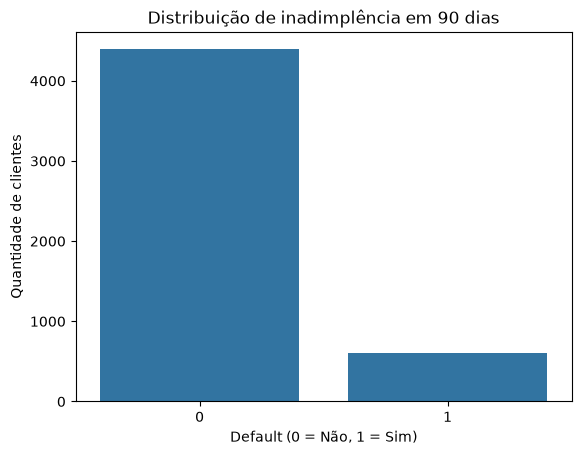

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="default_90d")

plt.title("Distribuição de inadimplência em 90 dias")
plt.xlabel("Default (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade de clientes")
plt.show()

# Verificar inconsistências

In [17]:
verificacoes = {
    "Idade negativa ou zero": (df["idade"] <= 0).sum(),
    "Renda negativa": (df["renda_mensal"] < 0).sum(),
    "Tempo de emprego negativo": (df["tempo_emprego_anos"] < 0).sum(),
    "Score fora de 300 a 900": (
        ~df["score_credito"].between(300, 900)
    ).sum(),
    "Valor solicitado não positivo": (
        df["valor_solicitado"] <= 0
    ).sum(),
    "Prazo não positivo": (df["prazo_meses"] <= 0).sum(),
    "Utilização fora de 0 a 1": (
        ~df["utilizacao_credito"].between(0, 1)
    ).sum(),
    "Target fora de 0 e 1": (
        ~df["default_90d"].isin([0, 1])
    ).sum()
}

display(
    pd.DataFrame(
        verificacoes.items(),
        columns=["Verificação", "Quantidade de inconsistências"]
    )
)

,Verificação,Quantidade de inconsistências
0,Idade negativa ou zero,0
1,Renda negativa,0
2,Tempo de emprego negativo,0
3,Score fora de 300 a 900,0
4,Valor solicitado não positivo,0
5,Prazo não positivo,0
6,Utilização fora de 0 a 1,0
7,Target fora de 0 e 1,0


Essas verificações são importantes porque dados inconsistentes podem prejudicar o treinamento do modelo.

# Identificar possíveis outliers
Vamos utilizar os quartis e o intervalo interquartil (IQR) para investigar valores extremos.

A fórmula:

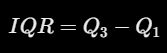

Os limites convencionais:

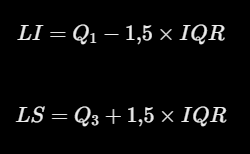

In [18]:
colunas_numericas = [
    "idade",
    "renda_mensal",
    "tempo_emprego_anos",
    "score_credito",
    "valor_solicitado",
    "utilizacao_credito"
]

resultados = []

for coluna in colunas_numericas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ).sum()

    resultados.append({
        "Variável": coluna,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Possíveis outliers": quantidade
    })

display(pd.DataFrame(resultados))

,Variável,Limite inferior,Limite superior,Possíveis outliers
0,idade,-8.000000,96.000000,0
1,renda_mensal,-3453.691250,11453.418750,294
2,tempo_emprego_anos,-6.067783,15.027267,16
3,score_credito,423.500000,883.500000,38
4,valor_solicitado,-9977.817500,28540.182500,335
5,utilizacao_credito,-0.199500,0.844500,35


#### Visualizar os outliers
Vamos utilizar boxplots

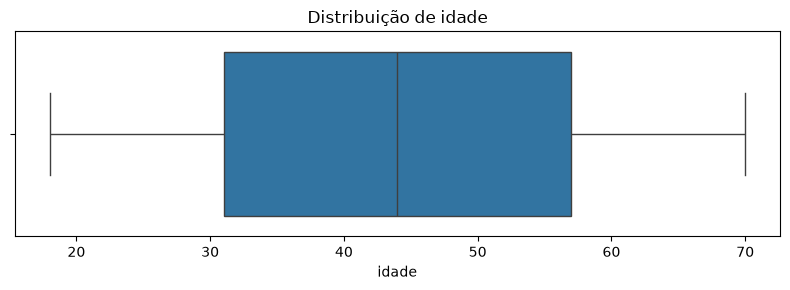

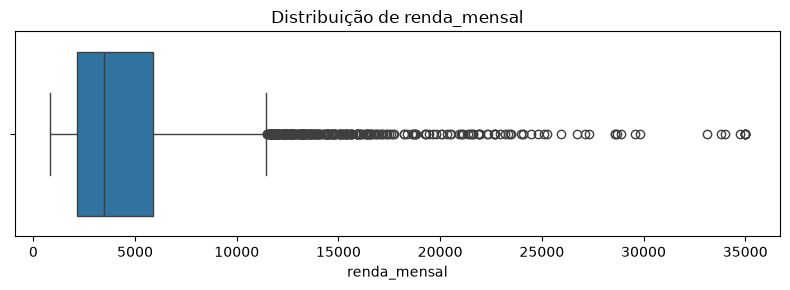

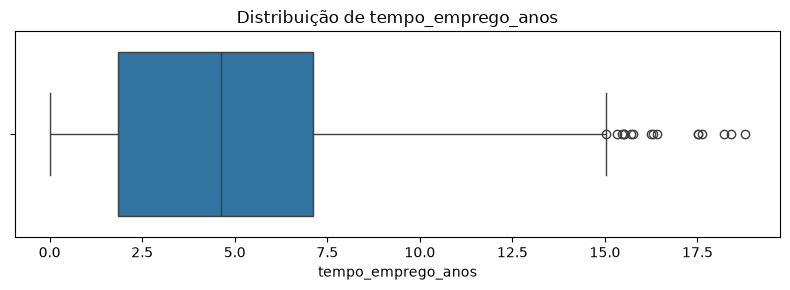

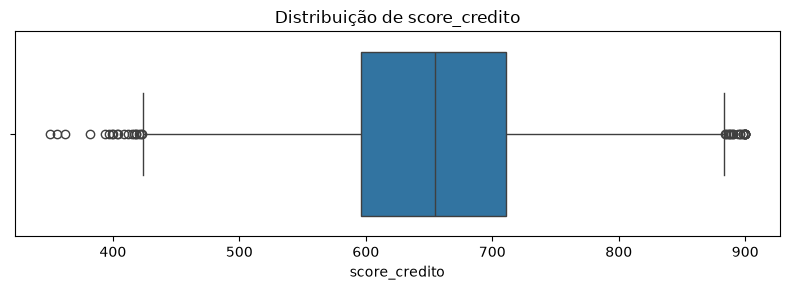

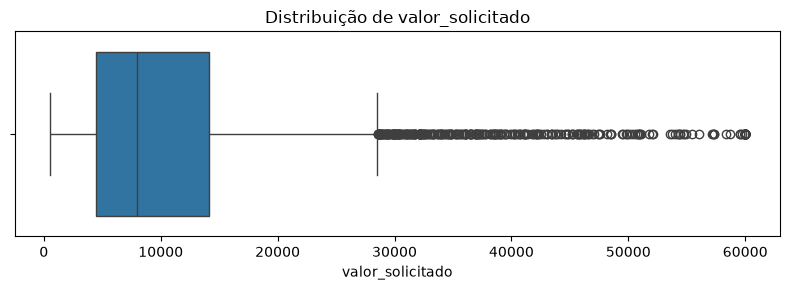

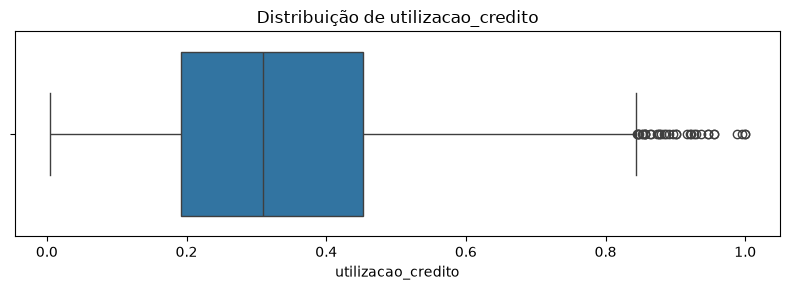

In [19]:
for coluna in colunas_numericas:
    plt.figure(figsize=(8, 3))

    sns.boxplot(data=df, x=coluna)

    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.tight_layout()
    plt.show()